In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

In [3]:
# Load the Iris dataset built into scikit-learn
iris = load_iris()

# Convert to a DataFrame and add the species name as a column
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [5]:
print("Shape of dataset:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nNull values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSamples per species:")
print(df["species"].value_counts())

Shape of dataset: (150, 5)

Data types:
sepal length (cm)     float64
sepal width (cm)      float64
petal length (cm)     float64
petal width (cm)      float64
species              category
dtype: object

Null values per column:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Duplicate rows: 1

Samples per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [7]:
# Descriptive statistics
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


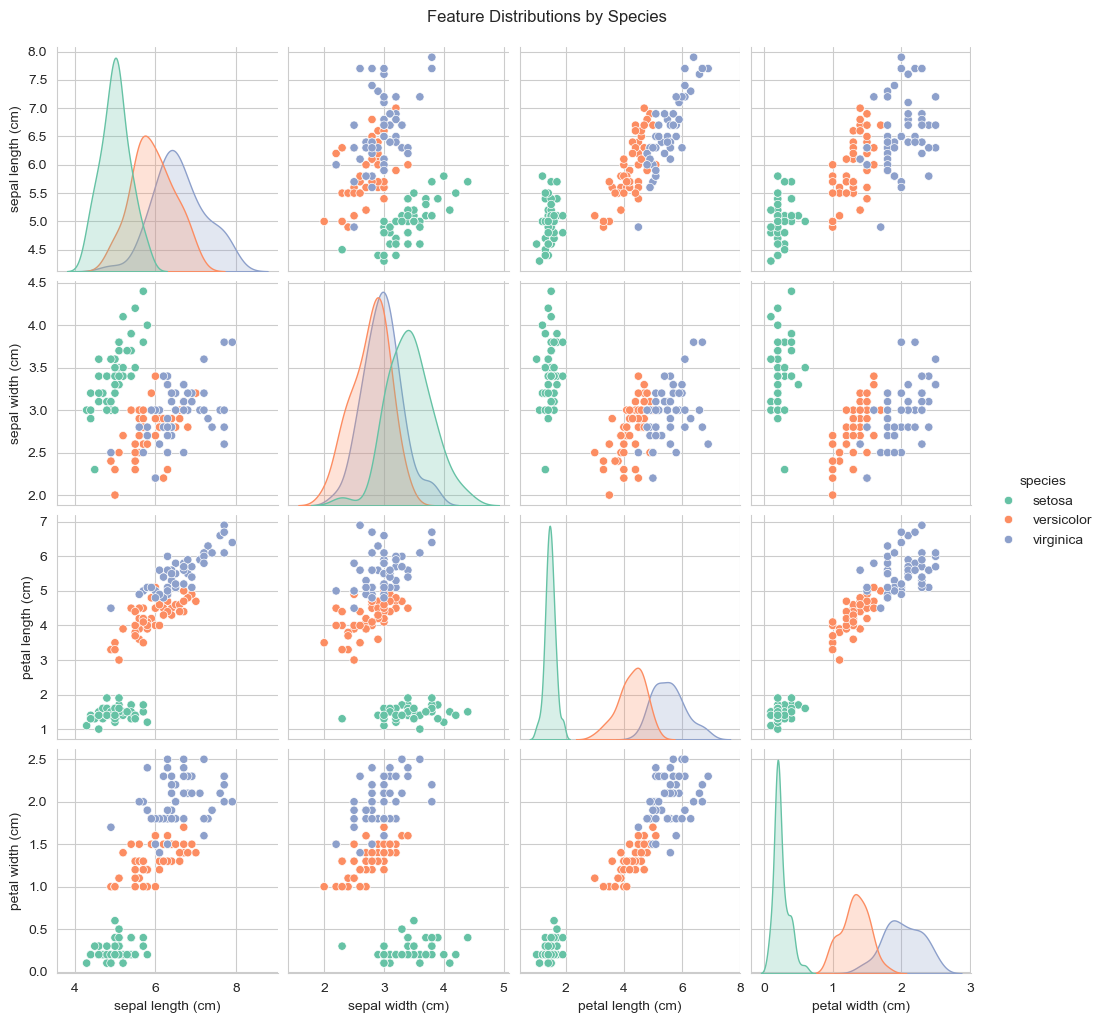

In [9]:
sns.pairplot(df, hue="species", palette="Set2", diag_kind="kde")
plt.suptitle("Feature Distributions by Species", y=1.02)
plt.show()

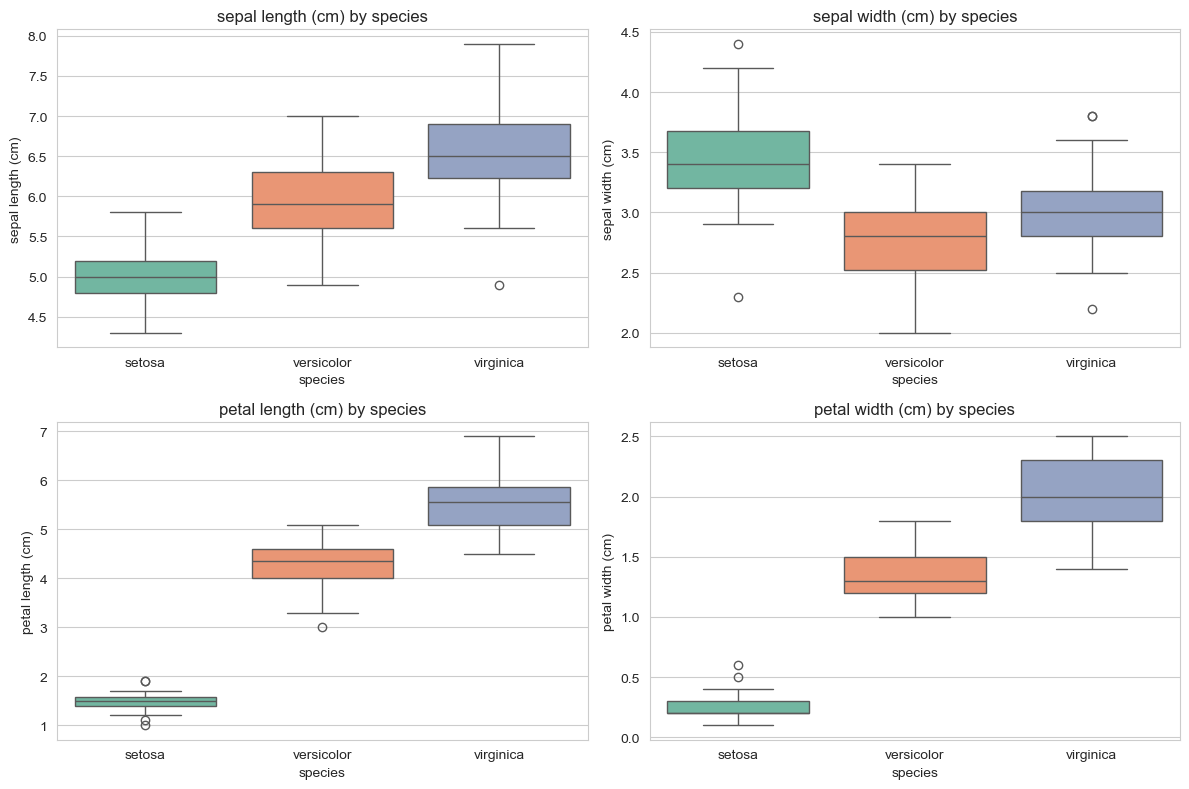

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), iris.feature_names):
    sns.boxplot(x="species", y=feature, data=df, palette="Set2", ax=ax)
    ax.set_title(f"{feature} by species")

plt.tight_layout()
plt.show()

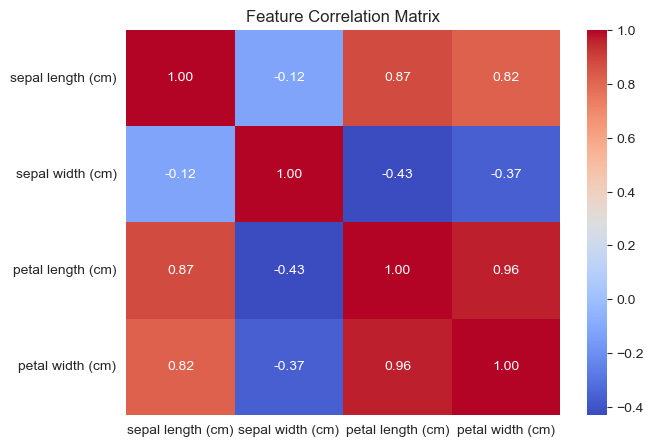

In [13]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

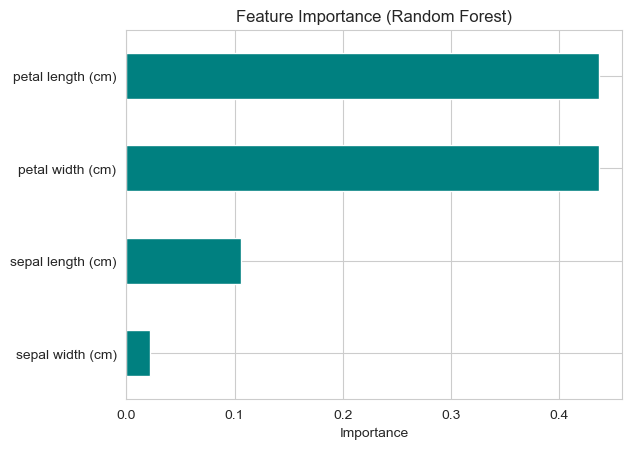

petal length (cm)    0.436130
petal width (cm)     0.436065
sepal length (cm)    0.106128
sepal width (cm)     0.021678
dtype: float64


In [15]:
X = df[iris.feature_names]
y = df["species"]

# Random Forest ranks features by how useful they are for classification
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

importance = pd.Series(rf.feature_importances_, index=iris.feature_names).sort_values()
importance.plot(kind="barh", color="teal", title="Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()

print(importance.sort_values(ascending=False))

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (120, 4)
Testing set: (30, 4)


Logistic Regression
Test Accuracy: 0.9667

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



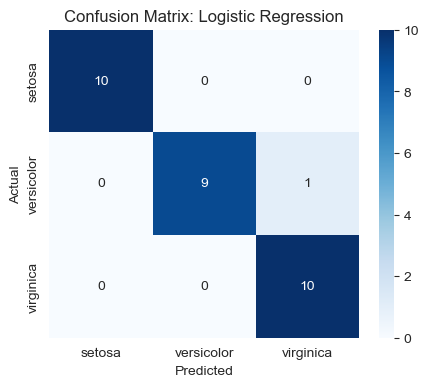

K-Nearest Neighbours
Test Accuracy: 1.0000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



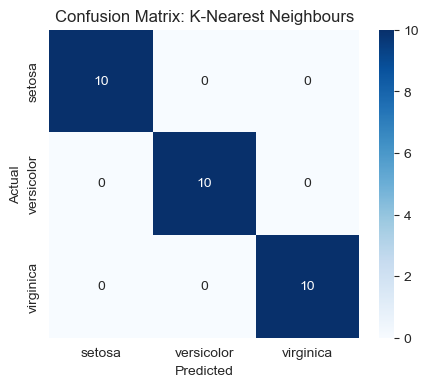

Decision Tree
Test Accuracy: 0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



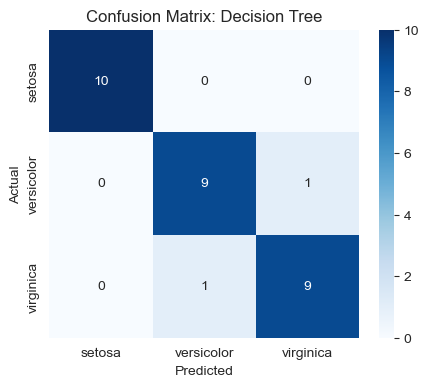

Random Forest
Test Accuracy: 0.9000

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



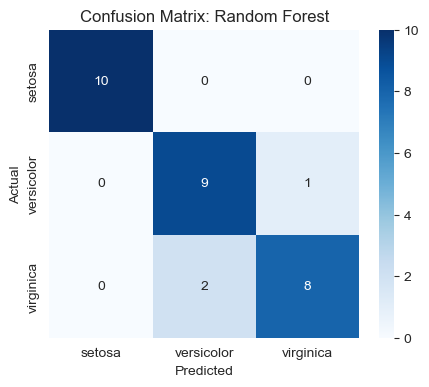

In [19]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "K-Nearest Neighbours": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = []

for name, model in models.items():
    # Train the model and predict on the test set
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Store test accuracy and 5-fold cross-validation accuracy
    test_acc = accuracy_score(y_test, y_pred)
    cv_acc = cross_val_score(model, X, y, cv=5).mean()
    results.append({"Model": name, "Test Accuracy": test_acc, "CV Accuracy": cv_acc})

    print("=" * 60)
    print(name)
    print("=" * 60)
    print(f"Test Accuracy: {test_acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=iris.target_names)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=iris.target_names, yticklabels=iris.target_names)
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

In [21]:
results_df = (
    pd.DataFrame(results)
    .sort_values(["CV Accuracy", "Test Accuracy"], ascending=False)
    .reset_index(drop=True)
)
results_df

,Model,Test Accuracy,CV Accuracy
0,K-Nearest Neighbours,1.000000,0.973333
1,Logistic Regression,0.966667,0.973333
2,Random Forest,0.900000,0.966667
3,Decision Tree,0.933333,0.953333


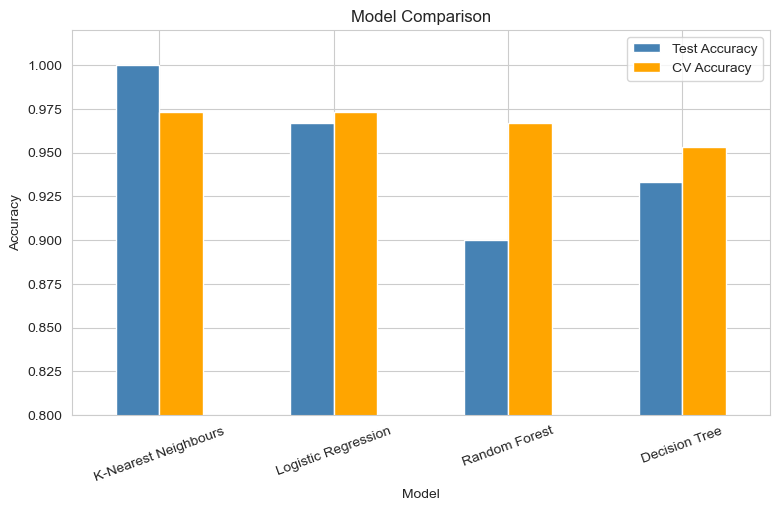

Best model: K-Nearest Neighbours
Test accuracy: 1.0000 | CV accuracy: 0.9733


In [23]:
results_df.set_index("Model")[["Test Accuracy", "CV Accuracy"]].plot(
    kind="bar", figsize=(9, 5), ylim=(0.8, 1.02), color=["steelblue", "orange"]
)
plt.title("Model Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

best = results_df.iloc[0]
print(f"Best model: {best['Model']}")
print(f"Test accuracy: {best['Test Accuracy']:.4f} | CV accuracy: {best['CV Accuracy']:.4f}")